# Demo: `P_fail` from Shape `.raw` files

**Input is only a Shape tree of `.raw` files** (`thick_*.raw` + `LogJacs_*.raw`, plus `curvature_*.raw` when present). No labels CSV.

This notebook uses the same `local_paths.py` knobs as `qc-report` (tau source, pairs, `MAX_SUBJECTS`). The shape tree scored below is the whole **TOP** site (`.../ENIGMA_SZ/TOP`), which discovery maps onto `TOP/TOP_SZ`. It does **not** write `OUT_DIR`.

Frozen pipeline per ROI:

`.raw` vertices -> **StandardScaler** -> **KernelPCA (RBF, 200)** -> **logistic** -> `P_fail` -> flag if `P_fail >= tau`

`tau` comes from `configs/interpolator.csv` if `DESIRED_RECALL` is set, else `configs/thresholds.csv`.


In [1]:
%matplotlib inline
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

from shapeqc.interpolate import load_interpolator_table, tau_from_table
from shapeqc.io import FEATURES_2CH, FEATURES_3CH, ROI_NAMES, iter_subjects, load_channels
from shapeqc.models_frozen import _unwrap_pipe, find_joblib
from shapeqc.score import run_score
from shapeqc.settings import load_local_settings, score_options_from_local

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 12})

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = ROOT.parent

local = load_local_settings()
if not local.shape_root or not local.model_3ch:
    raise SystemExit(
        "Set SHAPE_ROOT and MODEL_3CH in local_paths.py "
        "(copy local_paths.example.py). Input is a Shape .raw tree."
    )

opts = score_options_from_local(local)
# Whole TOP site, not one subject folder. Discovery uses TOP/TOP_SZ.
SHAPE_ROOT = Path(
    "/data01/bgutman/LEGACY/cygdrive/e/BG_back/ifs/loni/faculty/thompson/four_d/Artemis/Shape/ENIGMA_SZ/TOP"
)
MODEL_3CH = Path(local.model_3ch)
MODEL_2CH = Path(local.model_2ch) if local.model_2ch else None
INTERPOLATOR = Path(opts["interpolators"]) if opts["interpolators"] else (ROOT / "configs" / "interpolator.csv")
DESIRED_RECALL = opts["desired_recall"]
FOCUS_ROI = 17  # component breakdown; change to any scored ROI

print("shape tree", SHAPE_ROOT)
print("3ch models", MODEL_3CH)
print("max_subjects", opts["max_subjects"] or "all under SHAPE_ROOT")
print("desired_recall", DESIRED_RECALL)
print("pairs", opts["pairs"])
print("tau override", opts["tau_override"])
print("interpolator", INTERPOLATOR)


def roi_label(roi):
    return "{0}  {1}".format(int(roi), ROI_NAMES.get(int(roi), ""))


def sigmoid(z):
    z = np.clip(np.asarray(z, dtype=float), -40.0, 40.0)
    return 1.0 / (1.0 + np.exp(-z))


def logit(p):
    p = np.clip(float(p), 1e-9, 1.0 - 1e-9)
    return float(np.log(p / (1.0 - p)))


shape tree /data01/bgutman/LEGACY/cygdrive/e/BG_back/ifs/loni/faculty/thompson/four_d/Artemis/Shape/ENIGMA_SZ/TOP
3ch models /data01/ymaruyam/ADNI_FS/QC_ML/outputs/logistic_clean/curv_full_recall80/training
max_subjects all under SHAPE_ROOT
desired_recall None
pairs None
tau override None
interpolator /data01/ymaruyam/ADNI_FS/QC_ML_submit/configs/interpolator.csv


## 1. Interpolator: desired fail-recall -> tau

Labels are not passed at score time. This curve was fit on training validation scores. Lower recall -> higher tau -> fewer flags. Scoring uses this curve only when `DESIRED_RECALL` is set; otherwise `qc-report` uses `configs/thresholds.csv`.


,desired_recall,11 L-Caudate,13 L-Pallidum,17 L-Hippocampus,53 R-Hippocampus,pair 17_53
0,0.5,0.7757,0.8195,0.7859,0.5951,0.6380
1,0.6,0.4243,0.7553,0.6864,0.4867,0.4752
2,0.7,0.4243,0.7433,0.6393,0.4556,0.2701
3,0.8,0.3175,0.5471,0.5118,0.4352,0.1412
4,0.9,0.1747,0.3264,0.3616,0.2541,0.0256


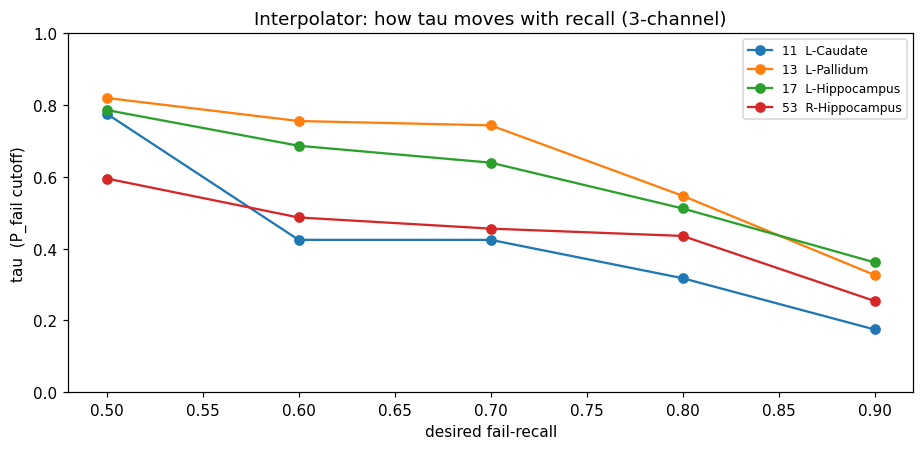

In [2]:
table = load_interpolator_table(INTERPOLATOR)
grid = (0.5, 0.6, 0.7, 0.8, 0.9)
show_rois = [11, 13, 17, 53]
rows = []
for rec in grid:
    recd = {"desired_recall": rec}
    for roi in show_rois:
        recd[roi_label(roi)] = tau_from_table(
            table, channel_set="thick+logjac+curv", roi=roi, desired_recall=rec
        )
    recd["pair 17_53"] = tau_from_table(
        table, channel_set="thick+logjac+curv", roi="17_53", desired_recall=rec
    )
    rows.append(recd)
tau_tbl = pd.DataFrame(rows)
display(tau_tbl.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
for roi in show_rois:
    ys = [tau_from_table(table, channel_set="thick+logjac+curv", roi=roi, desired_recall=r) for r in grid]
    ax.plot(grid, ys, marker="o", label=roi_label(roi))
if DESIRED_RECALL is not None:
    ax.axvline(DESIRED_RECALL, color="0.5", ls="--", lw=1, label="this run ({0})".format(DESIRED_RECALL))
ax.set_xlabel("desired fail-recall")
ax.set_ylabel("tau  (P_fail cutoff)")
ax.set_title("Interpolator: how tau moves with recall (3-channel)")
ax.set_ylim(0, 1)
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()


## 2. Score the TOP site

`SHAPE_ROOT` is the TOP site folder. Discovery keeps subject folders under `TOP/TOP_SZ` that contain `thick_*.raw` (522 subjects, 14 ROIs). Pair rows are added only if `PAIRS` is set in `local_paths.py`. This cell does not write `OUT_DIR`. The tables below are the per-ROI queue and the largest review margins, not one row per subject.


In [3]:
payload = run_score(
    SHAPE_ROOT,
    verify_checksums=True,
    **opts,
)
preds = pd.DataFrame(payload["predictions"])
assert "y_fail" not in preds.columns
singles = preds.loc[preds["pair"].fillna("") == ""].copy()
singles["roi"] = singles["roi"].astype(int)
order = sorted(singles["roi"].unique())

view = singles.copy()
view["margin"] = view["P_fail"] - view["tau"]
view["decision"] = np.where(view["flag"] == 1, "REVIEW", "ok")
view = view.sort_values(["margin", "P_fail"], ascending=False)

by_roi = (
    view.groupby(["roi", "roi_name"], as_index=False)
    .agg(
        n=("subject_id", "size"),
        n_review=("flag", "sum"),
        flagged_frac=("flag", "mean"),
        tau=("tau", "first"),
        P_fail_median=("P_fail", "median"),
        channel_set=("channel_set", "first"),
    )
    .sort_values("roi")
)
by_roi["n_review"] = by_roi["n_review"].astype(int)
display(Markdown(
    "**Per ROI on this site.** `flagged_frac` is the review queue, not a fail rate. "
    "Tau is the validation recall-floor and is not comparable across ROIs."
))
display(by_roi.round(4))

review = view.loc[view["flag"] == 1]
show = review[["subject_id", "roi", "roi_name", "P_fail", "tau", "margin", "decision", "channel_set"]].head(25).round(4)
display(Markdown(
    "**Largest margins in the review queue** (first 25 of {0}). `margin > 0` means `P_fail >= tau`.".format(len(review))
))
display(show)


shapeqc: skipped 12 non-shape folder(s): bilat_shape, stats_bil_logs, stats_bilateral, stats_bilateral_2017Jan16, stats_bilateral_apr14, stats_bilateral_logs, stats_bilateral_logs_apr14, stats_uni_logs, stats_uni_logs_apr14, stats_unilateral, stats_unilateral_2017Jan16, stats_unilateral_apr14


**Per ROI on this site.** `flagged_frac` is the review queue, not a fail rate. Tau is the validation recall-floor and is not comparable across ROIs.

,roi,roi_name,n,n_review,flagged_frac,tau,P_fail_median,channel_set
0,10,L-Thalamus,522,418,0.8008,0.0086,0.0296,thick+logjac+curv
1,11,L-Caudate,522,66,0.1264,0.3175,0.0745,thick+logjac+curv
2,12,L-Putamen,522,336,0.6437,0.2146,0.3122,thick+logjac+curv
3,13,L-Pallidum,522,105,0.2011,0.5471,0.0814,thick+logjac+curv
4,17,L-Hippocampus,522,79,0.1513,0.5118,0.1421,thick+logjac+curv
5,18,L-Amygdala,522,261,0.5000,0.1588,0.1588,thick+logjac+curv
6,26,L-Accumbens,522,2,0.0038,0.5107,0.0765,thick+logjac+curv
7,49,R-Thalamus,522,214,0.4100,0.2058,0.1760,thick+logjac+curv
8,50,R-Caudate,522,174,0.3333,0.0833,0.0298,thick+logjac+curv
9,51,R-Putamen,522,207,0.3966,0.1896,0.1393,thick+logjac+curv


**Largest margins in the review queue** (first 25 of 2591). `margin > 0` means `P_fail >= tau`.

,subject_id,roi,roi_name,P_fail,tau,margin,decision,channel_set
2436,top15_0567,10,L-Thalamus,0.9665,0.0086,0.9579,REVIEW,thick+logjac+curv
6818,top15_1290,10,L-Thalamus,0.9578,0.0086,0.9492,REVIEW,thick+logjac+curv
2100,top15_0485,10,L-Thalamus,0.9354,0.0086,0.9267,REVIEW,thick+logjac+curv
5530,top15_0997,10,L-Thalamus,0.9347,0.0086,0.9261,REVIEW,thick+logjac+curv
3032,top15_0664,50,R-Caudate,0.9985,0.0833,0.9153,REVIEW,thick+logjac+curv
2892,top15_0652,50,R-Caudate,0.9916,0.0833,0.9084,REVIEW,thick+logjac+curv
4096,top15_0780,50,R-Caudate,0.9610,0.0833,0.8777,REVIEW,thick+logjac+curv
5572,top15_1002,10,L-Thalamus,0.8829,0.0086,0.8742,REVIEW,thick+logjac+curv
6616,top15_1267,50,R-Caudate,0.9532,0.0833,0.8699,REVIEW,thick+logjac+curv
3438,top15_0702,50,R-Caudate,0.9298,0.0833,0.8465,REVIEW,thick+logjac+curv


## 3. Results: where each ROI sits vs its own tau

Same ROI order (10 … 58) on every figure. Color is the decision, not a deployable verdict. One subject: each ROI is a single point. A site folder plots every subject's `P_fail` on that ROI.


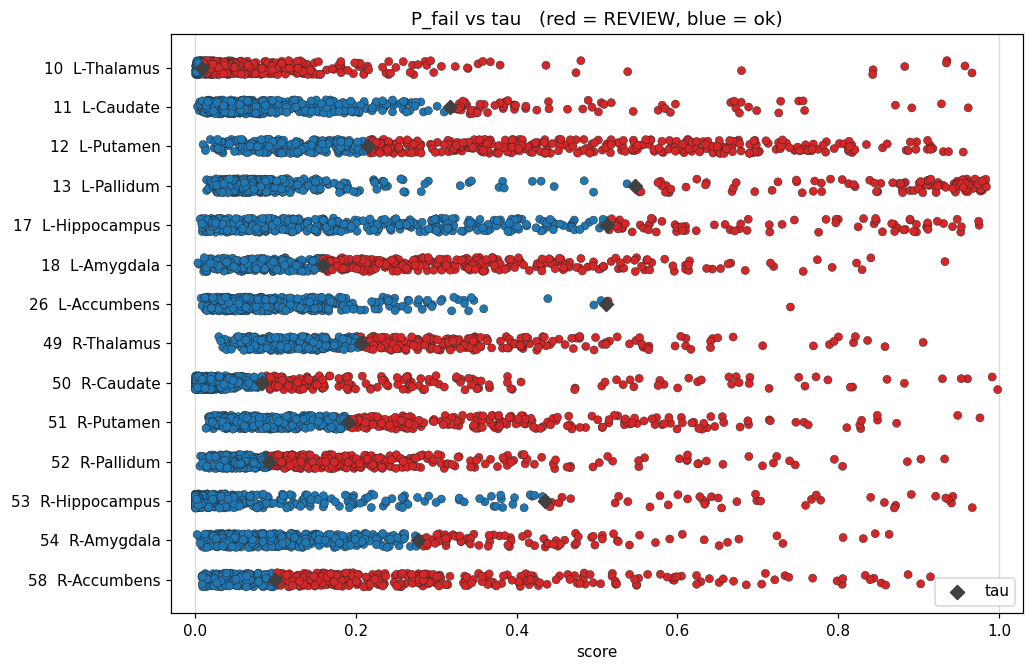

**2591 / 7308 rows flagged** across **522** subject(s) (training validation tau; override via local_paths.TAU). Largest margin: **10  L-Thalamus** (+0.958).

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 6.2))
y = np.arange(len(order))
rng = np.random.default_rng(0)
tau_drawn = False
for i, r in enumerate(order):
    sub = singles.loc[singles["roi"] == r]
    pf = sub["P_fail"].to_numpy(dtype=float)
    flags = sub["flag"].to_numpy(dtype=int)
    tau = float(sub["tau"].iloc[0])
    jitter = rng.uniform(-0.18, 0.18, size=len(pf)) if len(pf) > 1 else np.zeros(len(pf))
    colors = np.where(flags == 1, "#d62728", "#1f77b4")
    ax.scatter(pf, np.full(len(pf), i) + jitter, s=28, c=colors, zorder=4, edgecolors="0.15", linewidths=0.3)
    ax.scatter([tau], [i], marker="D", s=42, color="0.25", zorder=5, label="tau" if not tau_drawn else None)
    tau_drawn = True
ax.axvline(0, color="0.85", lw=0.8)
ax.axvline(1, color="0.85", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([roi_label(r) for r in order])
ax.set_xlabel("score")
ax.set_xlim(-0.03, 1.03)
ax.set_title("P_fail vs tau   (red = REVIEW, blue = ok)")
ax.legend(loc="lower right")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

n_subj = int(singles["subject_id"].nunique())
n_review = int(singles["flag"].sum())
tau_note = (
    "desired_recall={0}".format(DESIRED_RECALL)
    if DESIRED_RECALL is not None
    else payload["macro"]["threshold_source"]
)
display(Markdown(
    "**{0} / {1} rows flagged** across **{2}** subject(s) ({3}). Largest margin: **{4}** ({5:+.3f}).".format(
        n_review,
        len(singles),
        n_subj,
        tau_note,
        roi_label(int(view.iloc[0]["roi"])),
        float(view.iloc[0]["margin"]),
    )
))


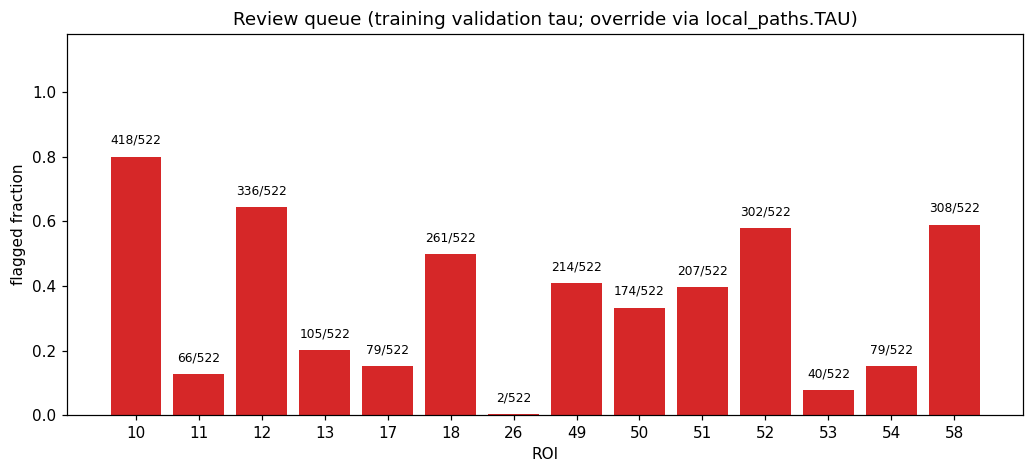

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
fracs = [float((singles.loc[singles["roi"] == r, "flag"] == 1).mean()) for r in order]
ns = [int(singles.loc[singles["roi"] == r].shape[0]) for r in order]
nflag = [int(singles.loc[singles["roi"] == r, "flag"].sum()) for r in order]
bar_c = ["#d62728" if f > 0 else "#1f77b4" for f in fracs]
ax.bar(np.arange(len(order)), fracs, color=bar_c)
for i, (frac, k, n) in enumerate(zip(fracs, nflag, ns)):
    ax.text(i, frac + 0.03, "{0}/{1}".format(k, n), ha="center", va="bottom", fontsize=8)
ax.set_xticks(np.arange(len(order)))
ax.set_xticklabels([str(r) for r in order])
ax.set_xlabel("ROI")
ax.set_ylabel("flagged fraction")
ax.set_title("Review queue ({0})".format(
    "desired_recall={0}".format(DESIRED_RECALL) if DESIRED_RECALL is not None else payload["macro"]["threshold_source"]
))
ax.set_ylim(0, 1.18)
fig.tight_layout()
plt.show()


## 4. How KPCA and logistic produce `P_fail`

Each ROI has its **own** frozen pipeline (not shared components across ROIs):

```mermaid
flowchart LR
  raw[".raw vertices<br/>thick + logjac + curv"] --> scale["StandardScaler"]
  scale --> kpca["KernelPCA<br/>RBF * 200 components"]
  kpca --> z["z in R^200"]
  z --> lin["logistic: logit = w*z + b"]
  lin --> sig["P_fail = sigma(logit)"]
  sig --> cmp{"P_fail >= tau ?"}
  cmp -->|yes| rev[REVIEW]
  cmp -->|no| ok[ok]
```

**KPCA** folds ~7k vertex features into 200 kernel components `z`. **Logistic** is a weighted sum of those `z` values. Component `k` pushes fail-probability up when `z_k * w_k > 0`. The cutoff `tau` is applied **after** the sigmoid, which is the same as `logit >= logit(tau)` in linear space.


In [6]:
subj_map = {p.name: p for p in iter_subjects(SHAPE_ROOT, max_subjects=opts["max_subjects"])}
pipe_cache = {}


def unpack_row(row):
    roi = int(row["roi"])
    ch = str(row["channel_set"])
    feats = FEATURES_3CH if ch == "thick+logjac+curv" else FEATURES_2CH
    model_dir = MODEL_3CH if ch == "thick+logjac+curv" else MODEL_2CH
    if model_dir is None:
        raise SystemExit("Need MODEL_2CH for 2-channel row roi={0}".format(roi))
    key = (str(model_dir), roi)
    if key not in pipe_cache:
        pipe_cache[key] = _unwrap_pipe(joblib.load(find_joblib(roi, 42, model_dir)))
    pipe = pipe_cache[key]
    x = load_channels(subj_map[row["subject_id"]], roi, features=feats, require=feats)
    z = pipe[:-1].transform(x.reshape(1, -1)).ravel()
    clf = pipe.named_steps["clf"]
    kpca = pipe.named_steps["transformer"]
    coef = clf.coef_.ravel()
    contrib = z * coef
    lin = float(contrib.sum() + clf.intercept_[0])
    return {
        "roi": roi,
        "roi_name": ROI_NAMES.get(roi, ""),
        "z": z,
        "coef": coef,
        "contrib": contrib,
        "intercept": float(clf.intercept_[0]),
        "logit": lin,
        "P_recon": float(sigmoid(lin)),
        "eig": np.asarray(getattr(kpca, "eigenvalues_", np.array([])), dtype=float),
        "kernel": getattr(kpca, "kernel", ""),
        "gamma": getattr(kpca, "gamma", None),
        "n_in": int(getattr(pipe, "n_features_in_", x.size)),
        "n_comp": int(z.size),
    }


demo_sid = str(view.iloc[0]["subject_id"])
demo = singles.loc[singles["subject_id"] == demo_sid].copy()
unpacked = [unpack_row(row) for _, row in demo.iterrows()]
uframe = pd.DataFrame(
    {
        "roi": [u["roi"] for u in unpacked],
        "roi_name": [u["roi_name"] for u in unpacked],
        "n_vertices_x3": [u["n_in"] for u in unpacked],
        "n_kpca": [u["n_comp"] for u in unpacked],
        "kernel": [u["kernel"] for u in unpacked],
        "logit": [u["logit"] for u in unpacked],
        "P_fail_from_logit": [u["P_recon"] for u in unpacked],
        "P_fail": [float(demo.loc[demo["roi"] == u["roi"], "P_fail"].iloc[0]) for u in unpacked],
        "logit_tau": [logit(float(demo.loc[demo["roi"] == u["roi"], "tau"].iloc[0])) for u in unpacked],
        "tau": [float(demo.loc[demo["roi"] == u["roi"], "tau"].iloc[0]) for u in unpacked],
        "flag": [int(demo.loc[demo["roi"] == u["roi"], "flag"].iloc[0]) for u in unpacked],
    }
)
uframe["logit_margin"] = uframe["logit"] - uframe["logit_tau"]
display(Markdown(
    "Component breakdown for **{0}** (not every subject). Reconstructed `P_fail` from `sigma(w*z + b)` should match the scorer.".format(demo_sid)
))
display(uframe.round(4))


shapeqc: skipped 12 non-shape folder(s): bilat_shape, stats_bil_logs, stats_bilateral, stats_bilateral_2017Jan16, stats_bilateral_apr14, stats_bilateral_logs, stats_bilateral_logs_apr14, stats_uni_logs, stats_uni_logs_apr14, stats_unilateral, stats_unilateral_2017Jan16, stats_unilateral_apr14


Component breakdown for **top15_0567** (not every subject). Reconstructed `P_fail` from `sigma(w*z + b)` should match the scorer.

,roi,roi_name,n_vertices_x3,n_kpca,kernel,logit,P_fail_from_logit,P_fail,logit_tau,tau,flag,logit_margin
0,10,L-Thalamus,7506,400,rbf,3.3629,0.9665,0.9665,-4.7433,0.0086,1,8.1062
1,11,L-Caudate,7506,175,rbf,0.8411,0.6987,0.6987,-0.7651,0.3175,1,1.6062
2,12,L-Putamen,7506,50,rbf,-2.1582,0.1036,0.1036,-1.2974,0.2146,0,-0.8608
3,13,L-Pallidum,3762,500,rbf,-2.0105,0.1181,0.1181,0.1889,0.5471,0,-2.1995
4,17,L-Hippocampus,7506,200,rbf,-2.5245,0.0742,0.0742,0.0472,0.5118,0,-2.5717
5,18,L-Amygdala,4104,150,rbf,-0.6687,0.3388,0.3388,-1.6671,0.1588,1,0.9984
6,26,L-Accumbens,2790,500,rbf,-1.0876,0.2521,0.2521,0.0430,0.5107,0,-1.1306
7,49,R-Thalamus,7506,350,rbf,-0.9512,0.2786,0.2786,-1.3502,0.2058,1,0.3990
8,50,R-Caudate,7506,50,rbf,-3.7000,0.0241,0.0241,-2.3987,0.0833,0,-1.3013
9,51,R-Putamen,7506,25,rbf,-0.0253,0.4937,0.4937,-1.4525,0.1896,1,1.4272


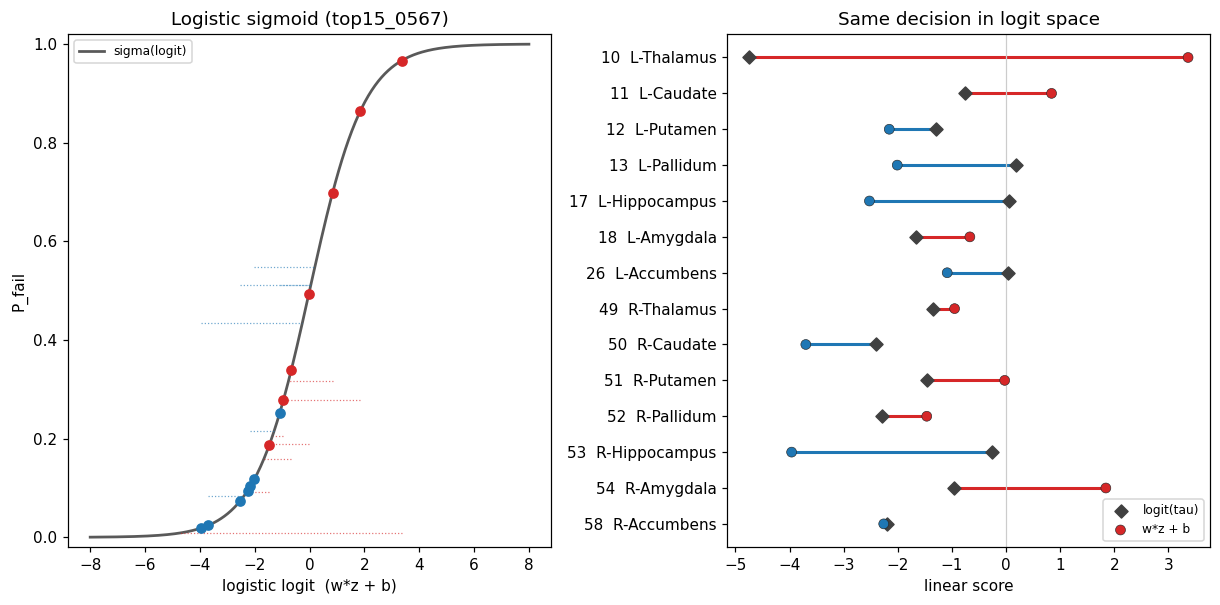

In [7]:
# Sigmoid: KPCA+logistic output in probability space, plus linear-space cutoff
fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.6))

xs = np.linspace(-8, 8, 400)
axes[0].plot(xs, sigmoid(xs), color="0.35", lw=1.8, label="sigma(logit)")
for u in unpacked:
    tau = float(demo.loc[demo["roi"] == u["roi"], "tau"].iloc[0])
    flag = int(demo.loc[demo["roi"] == u["roi"], "flag"].iloc[0])
    c = "#d62728" if flag else "#1f77b4"
    axes[0].scatter(u["logit"], u["P_recon"], color=c, s=36, zorder=3)
    axes[0].hlines(tau, u["logit"], logit(tau), colors=c, linestyles=":", lw=0.8, alpha=0.65)
axes[0].set_xlabel("logistic logit  (w*z + b)")
axes[0].set_ylabel("P_fail")
axes[0].set_title("Logistic sigmoid ({0})".format(demo_sid))
axes[0].set_ylim(-0.02, 1.02)
axes[0].legend(loc="upper left", fontsize=8)

demo_order = [int(u["roi"]) for u in unpacked]
y = np.arange(len(demo_order))
umap = {u["roi"]: u for u in unpacked}
lin = np.array([umap[r]["logit"] for r in demo_order])
ltau = np.array([logit(float(demo.loc[demo["roi"] == r, "tau"].iloc[0])) for r in demo_order])
fl = np.array([int(demo.loc[demo["roi"] == r, "flag"].iloc[0]) for r in demo_order])
col = np.where(fl == 1, "#d62728", "#1f77b4")
for i, (a, b, c) in enumerate(zip(ltau, lin, col)):
    axes[1].plot([a, b], [i, i], color=c, lw=2, zorder=2)
axes[1].scatter(ltau, y, marker="D", s=36, color="0.25", zorder=3, label="logit(tau)")
axes[1].scatter(lin, y, s=42, c=col, zorder=4, edgecolors="0.15", linewidths=0.4, label="w*z + b")
axes[1].axvline(0, color="0.8", lw=0.8)
axes[1].set_yticks(y)
axes[1].set_yticklabels([roi_label(r) for r in demo_order])
axes[1].set_xlabel("linear score")
axes[1].set_title("Same decision in logit space")
axes[1].invert_yaxis()
axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()


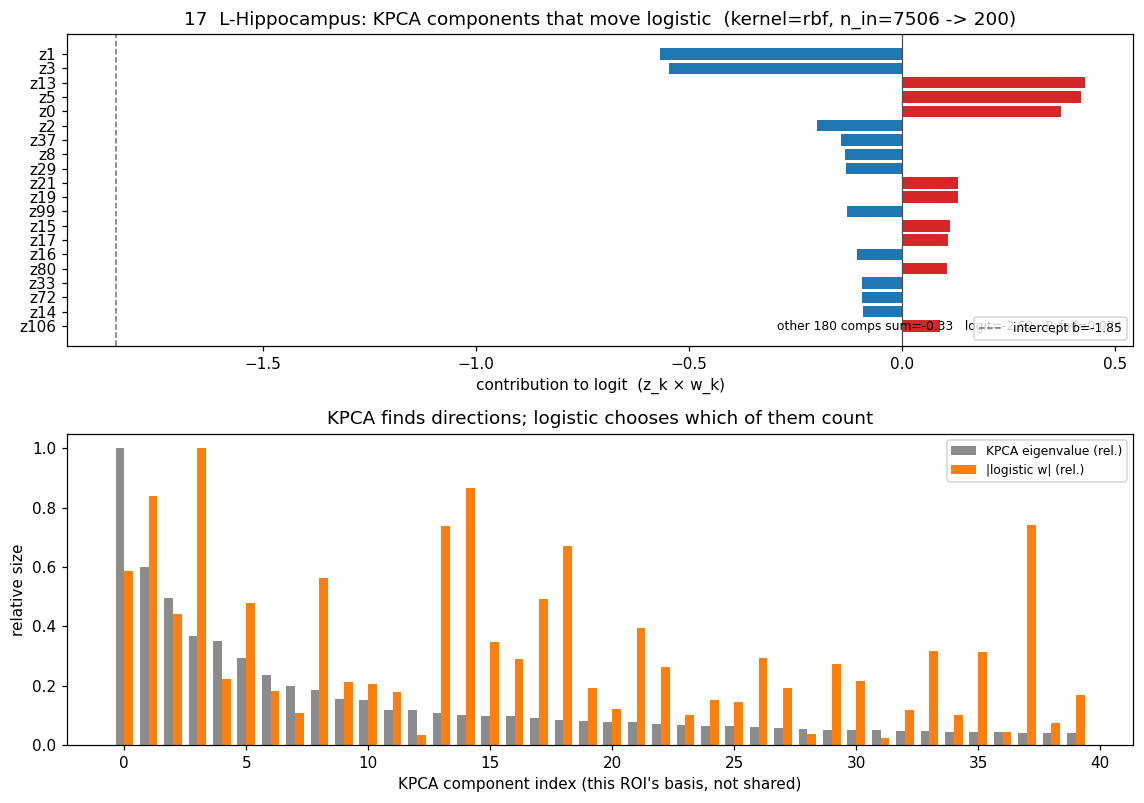

Top 20 logistic contributions for **17  L-Hippocampus**. Red bars push toward fail.

,component,z,w,z*w
0,z1,-0.1143,4.9818,-0.5692
1,z3,0.0923,-5.9278,-0.5471
2,z13,0.0978,4.3763,0.4279
3,z5,0.1480,2.8436,0.4207
4,z0,0.1070,3.4869,0.3733
5,z2,-0.0760,2.6281,-0.1998
6,z37,-0.0326,4.3925,-0.1432
7,z8,-0.0403,3.3412,-0.1345
8,z29,-0.0823,1.6120,-0.1326
9,z21,0.0555,2.3457,0.1302


In [8]:
focus = next((u for u in unpacked if u["roi"] == int(FOCUS_ROI)), unpacked[0])
k = np.arange(focus["n_comp"])
contrib = focus["contrib"]
order_k = np.argsort(-np.abs(contrib))
top_n = 20
top = order_k[:top_n]
rest = contrib[order_k[top_n:]].sum()

fig, axes = plt.subplots(2, 1, figsize=(10.5, 7.4), sharex=False)

cbar = ["#d62728" if v > 0 else "#1f77b4" for v in contrib[top]]
axes[0].barh(np.arange(top_n), contrib[top][::-1], color=list(reversed(cbar)))
axes[0].axvline(0, color="0.3", lw=0.8)
axes[0].axvline(focus["intercept"], color="0.45", ls="--", lw=1, label="intercept b={0:.2f}".format(focus["intercept"]))
axes[0].set_yticks(np.arange(top_n))
axes[0].set_yticklabels(["z{0}".format(i) for i in top[::-1]])
axes[0].set_xlabel("contribution to logit  (z_k × w_k)")
axes[0].set_title(
    "{0}: KPCA components that move logistic  (kernel={1}, n_in={2} -> {3})".format(
        roi_label(focus["roi"]), focus["kernel"], focus["n_in"], focus["n_comp"]
    )
)
axes[0].legend(loc="lower right", fontsize=8)
axes[0].text(
    0.99,
    0.04,
    "other {0} comps sum={1:+.2f}   logit={2:.2f}   P_fail={3:.3f}".format(
        focus["n_comp"] - top_n, rest, focus["logit"], focus["P_recon"]
    ),
    transform=axes[0].transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
)

eig = focus["eig"]
coef_abs = np.abs(focus["coef"])
nshow = min(40, focus["n_comp"])
axes[1].bar(np.arange(nshow) - 0.18, (eig[:nshow] / eig[:nshow].max()) if eig.size else np.zeros(nshow), width=0.36, label="KPCA eigenvalue (rel.)", color="0.55")
axes[1].bar(np.arange(nshow) + 0.18, coef_abs[:nshow] / coef_abs.max(), width=0.36, label="|logistic w| (rel.)", color="#ff7f0e")
axes[1].set_xlabel("KPCA component index (this ROI's basis, not shared)")
axes[1].set_ylabel("relative size")
axes[1].set_title("KPCA finds directions; logistic chooses which of them count")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

parts = pd.DataFrame(
    {
        "component": ["z{0}".format(i) for i in top],
        "z": focus["z"][top],
        "w": focus["coef"][top],
        "z*w": contrib[top],
    }
)
display(Markdown("Top {0} logistic contributions for **{1}**. Red bars push toward fail.".format(top_n, roi_label(focus["roi"]))))
display(parts.round(4))


## 5. Same `P_fail`, different recall targets

KPCA and logistic do not change. Only `tau` (and therefore `flag`) moves - no extra model loads.


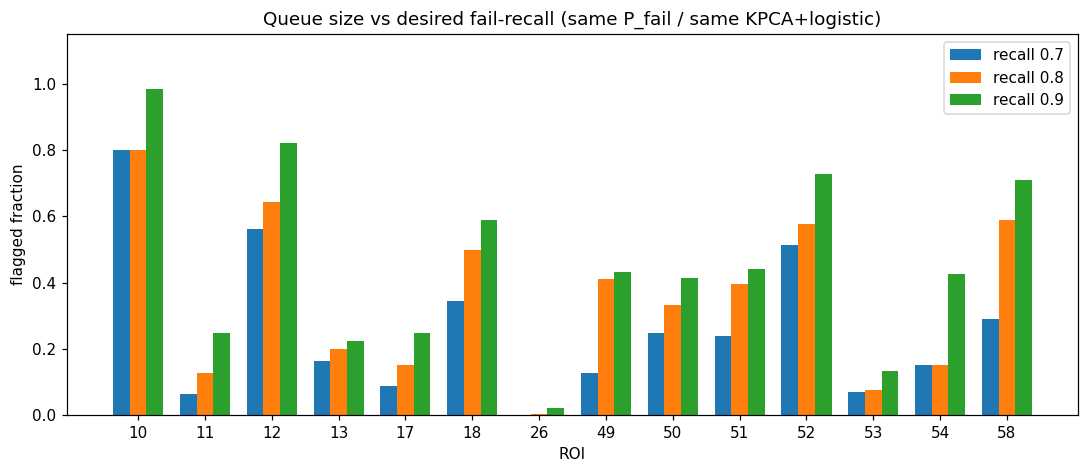

,roi,roi_name,n,review_0_7,review_0_8,review_0_9
0,10,L-Thalamus,522,0.801,0.801,0.985
1,11,L-Caudate,522,0.063,0.126,0.247
2,12,L-Putamen,522,0.561,0.644,0.822
3,13,L-Pallidum,522,0.165,0.201,0.224
4,17,L-Hippocampus,522,0.088,0.151,0.249
5,18,L-Amygdala,522,0.345,0.500,0.590
6,26,L-Accumbens,522,0.002,0.004,0.023
7,49,R-Thalamus,522,0.128,0.410,0.433
8,50,R-Caudate,522,0.247,0.333,0.414
9,51,R-Putamen,522,0.238,0.397,0.441


In [9]:
def flags_at_recall(frame, desired):
    out = []
    for _, row in frame.iterrows():
        tau = tau_from_table(
            table,
            channel_set=row["channel_set"],
            roi=row["roi"],
            desired_recall=desired,
        )
        out.append(int(float(row["P_fail"]) >= tau))
    return out

recalls = (0.7, 0.8, 0.9)
cmp = singles.copy()
for rec in recalls:
    cmp["flag_r{0}".format(rec)] = flags_at_recall(cmp, rec)

fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(order))
width = 0.25
for j, rec in enumerate(recalls):
    fracs = []
    for r in order:
        sub = cmp.loc[cmp["roi"] == r]
        fracs.append(float(sub["flag_r{0}".format(rec)].mean()) if len(sub) else float("nan"))
    ax.bar(x + (j - 1) * width, fracs, width=width, label="recall {0}".format(rec))
ax.set_xticks(x)
ax.set_xticklabels([str(r) for r in order])
ax.set_xlabel("ROI")
ax.set_ylabel("flagged fraction")
ax.set_title("Queue size vs desired fail-recall (same P_fail / same KPCA+logistic)")
ax.set_ylim(0, 1.15)
ax.legend()
fig.tight_layout()
plt.show()

display(
    cmp.groupby(["roi", "roi_name"], as_index=False)
    .agg(
        n=("subject_id", "size"),
        review_0_7=("flag_r0.7", "mean"),
        review_0_8=("flag_r0.8", "mean"),
        review_0_9=("flag_r0.9", "mean"),
    )
    .sort_values("roi")
    .round(3)
)
